# Making sense of lineage data

This notebook pulls everything the previous stages sent to Marquez through its REST API, loads the
lineage graph into `networkx` and answers the questions lineage is usually used for:

1. What is in Marquez? (jobs, run states, datasets)
2. **Impact analysis**: what is downstream of a dataset / column?
3. **Root cause analysis**: why is a dataset stale or broken?
4. **Column lineage**: which jobs touch a column?
5. **Schema drift**: what changed between dataset versions?
6. **Data quality** and raw events

Run `./demo.sh` first so there is something to look at.

In [1]:
import json
from urllib.parse import quote

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests

API = "http://localhost:9000/api/v1"
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 100)


def get(path, **params):
    r = requests.get(f"{API}{path}", params=params, timeout=30)
    r.raise_for_status()
    return r.json()


def enc(s):
    """URL-encode a namespace / dataset / job name for use inside a path."""
    return quote(s, safe="")

## 1. What is in Marquez?

In [2]:
namespaces = [n["name"] for n in get("/namespaces")["namespaces"]]
print(namespaces)

rows = []
for ns in namespaces:
    for j in get(f"/namespaces/{enc(ns)}/jobs", limit=1000)["jobs"]:
        latest = j.get("latestRun") or {}
        rows.append({
            "namespace": ns,
            "job": j["name"],
            "latest_state": latest.get("state"),
            "latest_duration_s": (latest.get("durationMs") or 0) / 1000,
            "inputs": len(j["inputs"]),
            "outputs": len(j["outputs"]),
        })
jobs = pd.DataFrame(rows)
jobs.sort_values(["namespace", "job"]).reset_index(drop=True)

['default', 'file://localhost', 'file://openlineage-poc', 'poc_dbt', 'poc_python_pipeline', 'poc_raw_events', 'postgres://localhost:5433']


,namespace,job,latest_state,latest_duration_s,inputs,outputs
0,poc_dbt,dbt-run-shop,COMPLETED,2.180,0,0
1,poc_dbt,dbt-run-shop.warehouse.public.shop.dim_customer_ltv,COMPLETED,0.032,2,1
2,poc_dbt,dbt-run-shop.warehouse.public.shop.dim_customer_ltv.test,COMPLETED,0.000,1,0
3,poc_dbt,dbt-run-shop.warehouse.public.shop.fct_daily_revenue,COMPLETED,0.039,1,1
4,poc_dbt,dbt-run-shop.warehouse.public.shop.fct_daily_revenue.test,COMPLETED,0.000,1,0
5,poc_dbt,dbt-run-shop.warehouse.public.shop.stg_customers,COMPLETED,0.048,1,1
6,poc_dbt,dbt-run-shop.warehouse.public.shop.stg_customers.test,COMPLETED,0.000,1,0
7,poc_dbt,dbt-run-shop.warehouse.public.shop.stg_orders,COMPLETED,0.037,1,1
8,poc_dbt,dbt-run-shop.warehouse.public.shop.stg_orders.test,COMPLETED,0.000,1,0
9,poc_python_pipeline,daily_pipeline,FAILED,1.298,0,0


In [3]:
# State of the latest run per job - anything that is not COMPLETED deserves a look
jobs.groupby(["namespace", "latest_state"]).size().unstack(fill_value=0)

latest_state,COMPLETED,FAILED
namespace,,
poc_dbt,9,0
poc_python_pipeline,2,2
poc_raw_events,2,2


## 2. Load the lineage graph into networkx

`GET /lineage?nodeId=...&depth=N` returns the connected neighbourhood of one node.
To get everything we ask for every dataset and merge the results.

In [4]:
def all_datasets():
    for ns in namespaces:
        for d in get(f"/namespaces/{enc(ns)}/datasets", limit=1000)["datasets"]:
            yield d["id"]["namespace"], d["id"]["name"]


def build_graph():
    g = nx.DiGraph()
    for ns, name in all_datasets():
        payload = get("/lineage", nodeId=f"dataset:{ns}:{name}", depth=50)
        for node in payload["graph"]:
            g.add_node(node["id"], kind=node["type"].lower(), data=node["data"])
            for edge in node["outEdges"]:
                g.add_edge(edge["origin"], edge["destination"])
    return g


G = build_graph()
datasets_n = sum(1 for _, d in G.nodes(data=True) if d["kind"] == "dataset")
print(f"{G.number_of_nodes()} nodes ({datasets_n} datasets, {G.number_of_nodes() - datasets_n} jobs), {G.number_of_edges()} edges")
print("connected components (weakly):", nx.number_weakly_connected_components(G))

25 nodes (11 datasets, 14 jobs), 25 edges
connected components (weakly): 2


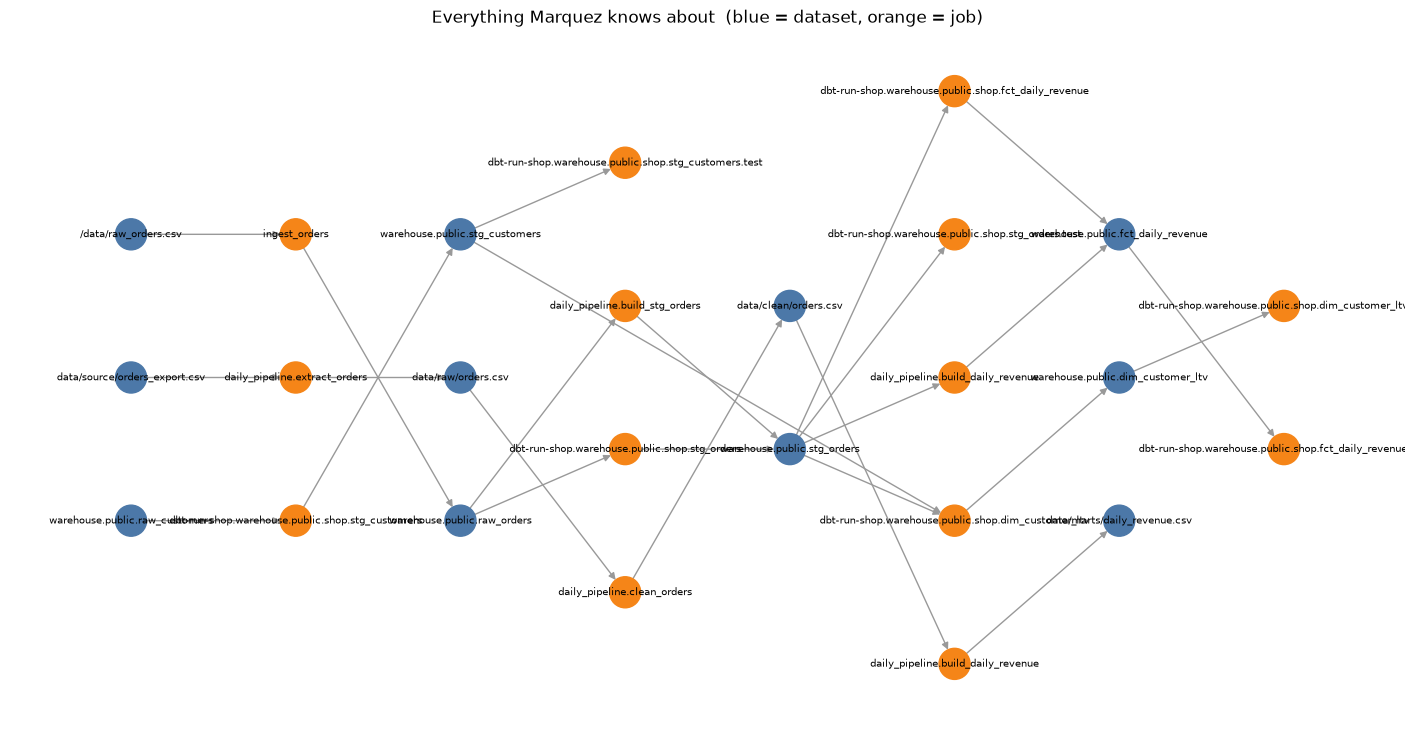

In [5]:
def short(node_id):
    kind, rest = node_id.split(":", 1)
    return rest.split(":")[-1] if kind == "dataset" else rest.split(":", 1)[-1]


def draw(g, title=""):
    # layered layout: position = longest distance from a source
    for layer, nodes in enumerate(nx.topological_generations(g)):
        for n in nodes:
            g.nodes[n]["layer"] = layer
    pos = nx.multipartite_layout(g, subset_key="layer", scale=3)
    colors = ["#4c78a8" if g.nodes[n]["kind"] == "dataset" else "#f58518" for n in g.nodes]
    plt.figure(figsize=(18, 9))
    nx.draw_networkx(g, pos, labels={n: short(n) for n in g.nodes}, node_color=colors, node_size=500,
                     font_size=7, arrows=True, edge_color="#999")
    plt.title(title + "  (blue = dataset, orange = job)")
    plt.axis("off")
    plt.show()


draw(G, "Everything Marquez knows about")

## 3. Impact analysis: what is downstream of a dataset?

"If I change or lose `warehouse.public.raw_orders`, what breaks?" is just a graph traversal.

In [6]:
def node_id(name, namespace=None):
    matches = [n for n, d in G.nodes(data=True)
               if d["kind"] == "dataset" and d["data"]["name"] == name
               and (namespace is None or d["data"]["namespace"] == namespace)]
    assert len(matches) == 1, matches
    return matches[0]


def impact(dataset_name):
    start = node_id(dataset_name)
    down = nx.descendants(G, start)
    return pd.DataFrame(
        [{"kind": G.nodes[n]["kind"], "name": short(n),
          "hops": nx.shortest_path_length(G, start, n)} for n in down]
    ).sort_values(["hops", "kind", "name"]).reset_index(drop=True)


impact("warehouse.public.raw_orders")

,kind,name,hops
0,job,daily_pipeline.build_stg_orders,1
1,job,dbt-run-shop.warehouse.public.shop.stg_orders,1
2,dataset,warehouse.public.stg_orders,2
3,job,daily_pipeline.build_daily_revenue,3
4,job,dbt-run-shop.warehouse.public.shop.dim_customer_ltv,3
5,job,dbt-run-shop.warehouse.public.shop.fct_daily_revenue,3
6,job,dbt-run-shop.warehouse.public.shop.stg_orders.test,3
7,dataset,warehouse.public.dim_customer_ltv,4
8,dataset,warehouse.public.fct_daily_revenue,4
9,job,dbt-run-shop.warehouse.public.shop.dim_customer_ltv.test,5


In [7]:
# Same question in reverse: where does a dataset come from?
def provenance(dataset_name):
    start = node_id(dataset_name)
    up = nx.ancestors(G, start)
    return pd.DataFrame(
        [{"kind": G.nodes[n]["kind"], "name": short(n),
          "hops": nx.shortest_path_length(G, n, start)} for n in up]
    ).sort_values(["hops", "kind", "name"]).reset_index(drop=True)


provenance("data/marts/daily_revenue.csv")

,kind,name,hops
0,job,daily_pipeline.build_daily_revenue,1
1,dataset,data/clean/orders.csv,2
2,job,daily_pipeline.clean_orders,3
3,dataset,data/raw/orders.csv,4
4,job,daily_pipeline.extract_orders,5
5,dataset,data/source/orders_export.csv,6


## 4. Root cause analysis: which upstream job failed?

For every dataset, look at the latest run of the job that writes it. A dataset is *suspect* if its
producer failed or if any producer further upstream failed.

In [8]:
def latest_run(job_node):
    # the job resource knows its latest run; /jobs/runs/{id} adds the run facets (errorMessage, parent, ...)
    _, ns, name = job_node.split(":", 2)
    job = get(f"/namespaces/{enc(ns)}/jobs/{enc(name)}")
    return get(f"/jobs/runs/{job['latestRun']['id']}") if job.get("latestRun") else None


job_status = {}
for n, d in G.nodes(data=True):
    if d["kind"] == "job":
        run = latest_run(n)
        job_status[n] = run["state"] if run else "NO_RUNS"

failed_jobs = [n for n, s in job_status.items() if s == "FAILED"]
print("jobs whose latest run FAILED:")
for n in failed_jobs:
    print("  -", short(n))

jobs whose latest run FAILED:
  - daily_pipeline.build_daily_revenue
  - daily_pipeline.clean_orders


In [9]:
rows = []
for n, d in G.nodes(data=True):
    if d["kind"] != "dataset":
        continue
    upstream_failed = [short(j) for j in nx.ancestors(G, n) | {n}
                       if G.nodes[j]["kind"] == "job" and job_status.get(j) == "FAILED"]
    if upstream_failed:
        rows.append({"dataset": short(n), "possibly stale because of": ", ".join(sorted(upstream_failed))})
pd.DataFrame(rows)

,dataset,possibly stale because of
0,warehouse.public.fct_daily_revenue,daily_pipeline.build_daily_revenue
1,data/clean/orders.csv,daily_pipeline.clean_orders
2,data/marts/daily_revenue.csv,daily_pipeline.clean_orders


In [10]:
# Drill into one failure: the error message is in the errorMessage run facet
for n in failed_jobs:
    run = latest_run(n)
    msg = (run["facets"].get("errorMessage") or {}).get("message")
    print(f"{short(n)}\n  run {run['id']} ended {run.get('endedAt')}\n  error: {msg}\n")

daily_pipeline.build_daily_revenue
  run 3a62eda6-5d01-48a7-919f-3b8115fdbb76 ended 2026-10-24T10:23:14Z
  error: psycopg2.errors.UndefinedColumn: column "amount" does not exist

daily_pipeline.clean_orders
  run 01a16d6f-df68-7c1b-bafd-f66e2897b323 ended 2026-10-24T10:23:30.732664Z
  error: ValueError: injected failure in clean_orders (--fail-at)



## 5. Column lineage: which jobs and columns touch `amount_cents`?

`GET /column-lineage?nodeId=...` works at column granularity. Asking for a *dataset* node returns the
column edges feeding it; we do that for every dataset and merge the results into one column graph.
(Asking for `withDownstream=true` from a column of a source dataset that nothing has produced
returns nothing in this Marquez version, so building the full graph and traversing locally is more robust.)

In [11]:
def build_column_graph():
    cg = nx.DiGraph()
    for ns, name in all_datasets():
        try:
            payload = get("/column-lineage", nodeId=f"dataset:{ns}:{name}", depth=50)
        except requests.HTTPError as err:
            if err.response.status_code == 404:   # dataset has no column lineage at all
                continue
            raise
        for node in payload["graph"]:
            d = node["data"]
            cg.add_node(node["id"], namespace=d["namespace"], dataset=d["dataset"], field=d["field"])
            for e in node["outEdges"]:
                cg.add_edge(e["origin"], e["destination"])
    return cg


CG = build_column_graph()
print(f"{CG.number_of_nodes()} columns, {CG.number_of_edges()} column-to-column edges")


def column_node(dataset, field):
    matches = [n for n, d in CG.nodes(data=True) if d["dataset"] == dataset and d["field"] == field]
    assert len(matches) == 1, matches
    return matches[0]

49 columns, 35 column-to-column edges


In [12]:
# Impact analysis at column level: everything derived from raw_orders.amount_cents
start = column_node("warehouse.public.raw_orders", "amount_cents")
pd.DataFrame(
    [{"dataset": CG.nodes[n]["dataset"], "column": CG.nodes[n]["field"],
      "hops": nx.shortest_path_length(CG, start, n)} for n in nx.descendants(CG, start)]
).sort_values(["hops", "dataset"]).reset_index(drop=True)

,dataset,column,hops
0,warehouse.public.stg_orders,amount,1
1,warehouse.public.dim_customer_ltv,lifetime_value,2
2,warehouse.public.fct_daily_revenue,avg_order_value,2
3,warehouse.public.fct_daily_revenue,revenue,2


In [13]:
# Provenance: where does revenue in the python mart come from, back to the source export?
end = column_node("data/marts/daily_revenue.csv", "revenue")
pd.DataFrame(
    [{"dataset": CG.nodes[n]["dataset"], "column": CG.nodes[n]["field"],
      "hops_upstream": nx.shortest_path_length(CG, n, end)} for n in nx.ancestors(CG, end)]
).sort_values("hops_upstream").reset_index(drop=True)

,dataset,column,hops_upstream
0,data/clean/orders.csv,amount,1
1,data/raw/orders.csv,amount_cents,2
2,data/source/orders_export.csv,amount_cents,3


In [14]:
# Which jobs touch amount_cents? Combine the column graph with the job graph:
# a job "touches" a column if it reads or writes the dataset the column belongs to.
touched = {CG.nodes[n]["dataset"] for n in nx.descendants(CG, start) | {start}}
rows = []
for n, d in G.nodes(data=True):
    if d["kind"] != "job":
        continue
    ins = {short(p) for p in G.predecessors(n)}
    outs = {short(s) for s in G.successors(n)}
    if (ins | outs) & touched:
        rows.append({"job": short(n), "reads": sorted(ins & touched), "writes": sorted(outs & touched)})
pd.DataFrame(rows).sort_values("job").reset_index(drop=True)

,job,reads,writes
0,daily_pipeline.build_daily_revenue,[warehouse.public.stg_orders],[warehouse.public.fct_daily_revenue]
1,daily_pipeline.build_stg_orders,[warehouse.public.raw_orders],[warehouse.public.stg_orders]
2,dbt-run-shop.warehouse.public.shop.dim_customer_ltv,[warehouse.public.stg_orders],[warehouse.public.dim_customer_ltv]
3,dbt-run-shop.warehouse.public.shop.dim_customer_ltv.test,[warehouse.public.dim_customer_ltv],[]
4,dbt-run-shop.warehouse.public.shop.fct_daily_revenue,[warehouse.public.stg_orders],[warehouse.public.fct_daily_revenue]
5,dbt-run-shop.warehouse.public.shop.fct_daily_revenue.test,[warehouse.public.fct_daily_revenue],[]
6,dbt-run-shop.warehouse.public.shop.stg_orders,[warehouse.public.raw_orders],[warehouse.public.stg_orders]
7,dbt-run-shop.warehouse.public.shop.stg_orders.test,[warehouse.public.stg_orders],[]
8,ingest_orders,[],[warehouse.public.raw_orders]


## 6. Schema drift between dataset versions

Every run that writes a dataset creates a version (if the content description changed). Comparing the
`fields` of consecutive versions shows schema changes - `--schema-change` in stages 1 and 2 adds `coupon_code`.

In [15]:
def schema_history(namespace, dataset):
    versions = get(f"/namespaces/{enc(namespace)}/datasets/{enc(dataset)}/versions")["versions"]
    versions = [v for v in versions if v["fields"]]            # skip versions without schema
    versions.sort(key=lambda v: v["createdAt"])
    rows, previous = [], None
    for v in versions:
        cols = {f["name"]: f["type"] for f in v["fields"]}
        if previous is not None:
            added = sorted(set(cols) - set(previous))
            removed = sorted(set(previous) - set(cols))
            changed = sorted(c for c in cols if c in previous and cols[c] != previous[c])
        else:
            added, removed, changed = sorted(cols), [], []
        rows.append({"created_at": v["createdAt"], "version": v["version"][:8],
                     "n_columns": len(cols), "added": added, "removed": removed, "type_changed": changed})
        previous = cols
    return pd.DataFrame(rows)


schema_history("file://openlineage-poc", "data/raw/orders.csv")

,created_at,version,n_columns,added,removed,type_changed
0,2026-10-24T10:23:21.534958Z,ebb489f1,5,"[amount_cents, customer_id, extracted_at, order_id, order_ts]",[],[]
1,2026-10-24T10:23:25.620109Z,270a25dd,6,[coupon_code],[],[]
2,2026-10-24T10:23:29.585189Z,7135a0d3,5,[],[coupon_code],[]


In [16]:
schema_history("file://openlineage-poc", "data/clean/orders.csv")

,created_at,version,n_columns,added,removed,type_changed
0,2026-10-24T10:23:22.795470Z,734f8ae7,5,"[amount, customer_id, order_date, order_id, order_ts]",[],[]
1,2026-10-24T10:23:26.819990Z,ed970cbf,6,[coupon_code],[],[]


## 7. Data quality and run statistics from facets

Facets are free-form but standardised. The Python pipeline sends `dataQualityMetrics` (input side) and
`outputStatistics`; dbt-ol sends `dataQualityAssertions` for each dbt test.

In [17]:
rows = []
for ns, name in all_datasets():
    d = get(f"/namespaces/{enc(ns)}/datasets/{enc(name)}")
    facets = d.get("facets") or {}
    for a in (facets.get("dataQualityAssertions") or {}).get("assertions", []):
        rows.append({"dataset": name, "column": a.get("column"), "assertion": a["assertion"], "success": a["success"]})
assertions = pd.DataFrame(rows)
assertions

,dataset,column,assertion,success
0,warehouse.public.dim_customer_ltv,customer_id,not_null,True
1,warehouse.public.dim_customer_ltv,customer_id,unique,True
2,warehouse.public.fct_daily_revenue,order_date,not_null,True
3,warehouse.public.fct_daily_revenue,order_date,unique,True
4,warehouse.public.stg_customers,customer_id,not_null,True
5,warehouse.public.stg_customers,customer_id,unique,True
6,warehouse.public.stg_orders,customer_id,not_null,True
7,warehouse.public.stg_orders,order_id,not_null,True
8,warehouse.public.stg_orders,order_id,unique,True


In [18]:
# row counts across runs of the python pipeline, from the raw event store
events = get("/events/lineage", limit=500)["events"]
rows = []
for e in events:
    if e["eventType"] != "COMPLETE":
        continue
    for o in e.get("outputs") or []:
        stats = (o.get("outputFacets") or {}).get("outputStatistics")
        if stats and stats.get("rowCount") is not None:
            rows.append({"time": e["eventTime"], "job": e["job"]["name"], "dataset": o["name"], "rows": stats["rowCount"]})
pd.DataFrame(rows).sort_values("time").reset_index(drop=True)

,time,job,dataset,rows
0,2026-10-24T10:23:10Z,build_stg_orders,warehouse.public.stg_orders,9870
1,2026-10-24T10:23:21.534958Z,extract_orders,data/raw/orders.csv,500
2,2026-10-24T10:23:22.79547Z,clean_orders,data/clean/orders.csv,283
3,2026-10-24T10:23:24.045664Z,build_daily_revenue,data/marts/daily_revenue.csv,14
4,2026-10-24T10:23:25.620109Z,extract_orders,data/raw/orders.csv,500
5,2026-10-24T10:23:26.81999Z,clean_orders,data/clean/orders.csv,283
6,2026-10-24T10:23:28.015557Z,build_daily_revenue,data/marts/daily_revenue.csv,14
7,2026-10-24T10:23:29.585189Z,extract_orders,data/raw/orders.csv,500
8,2026-10-24T10:23:41.983313Z,warehouse.public.shop.dim_customer_ltv,warehouse.public.dim_customer_ltv,40
9,2026-10-24T10:23:41.983674Z,warehouse.public.shop.fct_daily_revenue,warehouse.public.fct_daily_revenue,14


## 8. The raw event stream

Marquez keeps every event it received. This is useful to answer "who sent this?" and to replay or audit.

In [19]:
ev = pd.DataFrame([{
    "time": e["eventTime"], "type": e["eventType"], "producer": e["producer"].split("/")[-1],
    "namespace": e["job"]["namespace"], "job": e["job"]["name"],
    "n_in": len(e.get("inputs") or []), "n_out": len(e.get("outputs") or []),
} for e in events])
ev.groupby(["namespace", "type"]).size().unstack(fill_value=0)

type,COMPLETE,FAIL,START
namespace,,,
poc_dbt,11,0,11
poc_python_pipeline,9,2,11
poc_raw_events,3,2,3


In [20]:
# One complete event, as received
sample = next(e for e in events if e["eventType"] == "COMPLETE" and e["job"]["name"].endswith("clean_orders"))
print(json.dumps(sample, indent=2)[:3500])

{
  "eventType": "COMPLETE",
  "eventTime": "2026-10-24T10:23:26.81999Z",
  "run": {
    "runId": "01a16d6f-d008-7dd4-b4d5-1e227e7a41c0",
    "facets": {
      "nominalTime": null,
      "parent": {
        "_producer": "https://github.com/OpenLineage/OpenLineage/tree/1.54.0/client/python",
        "_schemaURL": "https://openlineage.io/spec/facets/1-2-0/ParentRunFacet.json#/$defs/ParentRunFacet",
        "run": {
          "runId": "01a16d6f-cb54-747b-9223-7e0aeb8f4f25"
        },
        "job": {
          "namespace": "poc_python_pipeline",
          "name": "daily_pipeline"
        },
        "root": {
          "job": {
            "name": "daily_pipeline",
            "facets": {},
            "namespace": "poc_python_pipeline"
          },
          "run": {
            "runId": "01a16d6f-cb54-747b-9223-7e0aeb8f4f25",
            "facets": {}
          }
        }
      },
      "tags": {
        "tags": [
          {
            "key": "openlineage_client_version",
            "

## Ideas to explore next

* Fix the stage 1 failure with `stage1_raw_events/send.sh --rerun`, or break the python pipeline again with `--fail-at build_daily_revenue`, and re-run section 4.
* Add a PySpark or Airflow stage and see how a third producer's datasets connect (or fail to connect) - naming matters!
* Write a custom facet and query it with the SQL in `queries.sql`.